In [167]:
# Clona o repositório para o ambiente do Google Colab.
import os

repositorio = "/content/grupo-01-projeto_supervisionado-II"

if not os.path.exists(repositorio):
    !git clone https://github.com/especializacao-ia-pucsp/grupo-01-projeto_supervisionado-II.git


# 1. Preparação do ambiente

Esta etapa desenvolve o módulo de **Visão Computacional** do projeto. O objetivo é utilizar as imagens anexadas aos chamados como uma fonte adicional de informação para a classificação das categorias.

O fluxo desta etapa é:

1. carregar e inspecionar as imagens;
2. realizar o pré-processamento;
3. associar as imagens às categorias dos chamados;
4. construir uma CNN para classificação;
5. avaliar o desempenho e discutir as limitações do experimento.

Como o projeto possui uma abordagem multimodal, os resultados desta etapa serão posteriormente utilizados como referência para a integração com outras modalidades de dados.

In [168]:
from pathlib import Path

# Diretório raiz do projeto clonado no Google Colab.
raiz_projeto = Path("/content/grupo-01-projeto_supervisionado-II")


### 1.1 — Configuração da reprodutibilidade

In [169]:
import tensorflow as tf

SEED = 42
tf.keras.utils.set_random_seed(SEED)

# 2. Carregamento e inspeção das imagens

Nesta etapa são carregadas as imagens disponíveis no projeto e verificadas suas características básicas, como quantidade, formato e dimensões.

### 2.1 — Definição do caminho das imagens

O diretório abaixo contém as imagens anexadas aos chamados que serão utilizadas no módulo de Visão Computacional.

In [170]:
caminho_imagens = raiz_projeto / "data" / "raw" / "images"

print("Pasta de imagens:", caminho_imagens)


Pasta de imagens: /content/grupo-01-projeto_supervisionado-II/data/raw/images


### 2.2 — Carregamento dos dados dos chamados

Além das imagens, precisamos consultar o dataset original para obter a relação entre `image_path` e `target_category`. Essa relação será usada posteriormente para criar os rótulos supervisionados da CNN.

O dataset é carregado explicitamente neste notebook para que esta etapa possa ser reproduzida sem depender de variáveis criadas em outro notebook.

In [171]:
import pandas as pd

caminho_dados = raiz_projeto / "data" / "raw" / "chamados.csv"

df_original = pd.read_csv(caminho_dados)

print("Formato do dataset:", df_original.shape)


Formato do dataset: (5000, 44)


### 2.3 — Listagem das imagens

In [172]:
import os

os.listdir(caminho_imagens)

['office.png',
 'hr_portal.png',
 'cooler.png',
 'monitor.png',
 'login.png',
 'sap_erp.png',
 'browser.png',
 'recruitment.png',
 'default_finance.png',
 'access_denied.png',
 'email.png',
 'network.png',
 'vpn.png',
 'default_software.png',
 'default_hr.png',
 'finance_report.png',
 'default_network.png',
 'payroll.png',
 'mouse.png',
 'default_hardware.png',
 'motherboard.png',
 'keyboard.png',
 'default_access.png',
 'power_supply.png',
 'server.png',
 'hard_drive.png']

### 2.4 — Visualização de uma imagem

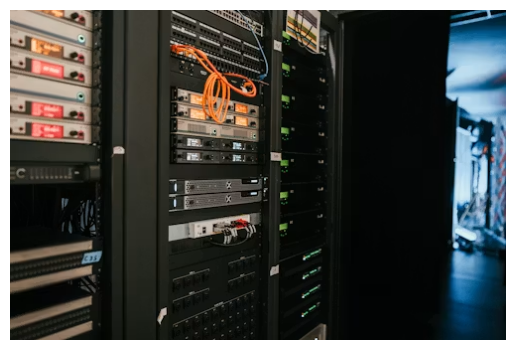

In [173]:
from PIL import Image
import matplotlib.pyplot as plt

imagem = Image.open(f"{caminho_imagens}/server.png")

plt.imshow(imagem)
plt.axis("off")
plt.show()

### 2.5 — Verificação das dimensões das imagens

In [174]:
for arquivo in os.listdir(caminho_imagens):
    if arquivo.endswith(".png"):
        imagem = Image.open(os.path.join(caminho_imagens, arquivo))
        print(arquivo, imagem.size)

office.png (500, 333)
hr_portal.png (323, 619)
cooler.png (500, 750)
monitor.png (500, 394)
login.png (500, 333)
sap_erp.png (612, 344)
browser.png (500, 333)
recruitment.png (500, 333)
default_finance.png (500, 750)
access_denied.png (612, 408)
email.png (500, 333)
network.png (500, 342)
vpn.png (500, 333)
default_software.png (612, 344)
default_hr.png (612, 408)
finance_report.png (738, 414)
default_network.png (500, 333)
payroll.png (612, 408)
mouse.png (500, 335)
default_hardware.png (612, 407)
motherboard.png (612, 408)
keyboard.png (500, 375)
default_access.png (191, 165)
power_supply.png (500, 375)
server.png (500, 333)
hard_drive.png (500, 334)


# 3. Pré-processamento das imagens

As imagens possuem dimensões diferentes e precisam ser convertidas para um formato padronizado antes de serem utilizadas pela CNN. Nesta etapa também é construída a relação entre cada imagem e sua categoria.

### 3.1 — Redimensionamento das imagens

As imagens originais possuem diferentes dimensões. Como uma CNN recebe entradas com formato fixo, todas as imagens são redimensionadas para **224 × 224 pixels**, mantendo três canais de cor (RGB).

In [175]:
from PIL import Image
import os

imagens_redimensionadas = []

for arquivo in os.listdir(caminho_imagens):

    if arquivo.lower().endswith((".png", ".jpg", ".jpeg")):

        caminho = os.path.join(caminho_imagens, arquivo)

        imagem = Image.open(caminho).convert("RGB")
        imagem = imagem.resize((224, 224))

        imagens_redimensionadas.append(imagem)

print("Imagens redimensionadas:", len(imagens_redimensionadas))

Imagens redimensionadas: 26


### 3.2 — Normalização dos pixels

Os valores dos pixels originalmente variam de **0 a 255**. Eles são divididos por 255 para colocá-los no intervalo **0 a 1**, facilitando o processamento numérico durante o treinamento da rede.

In [176]:
import numpy as np

imagens_normalizadas = []

for imagem in imagens_redimensionadas:

    imagem_array = np.array(imagem)

    imagem_normalizada = imagem_array / 255.0

    imagens_normalizadas.append(imagem_normalizada)

print("Quantidade de imagens:", len(imagens_normalizadas))
print("Valor mínimo:", imagens_normalizadas[0].min())
print("Valor máximo:", imagens_normalizadas[0].max())

Quantidade de imagens: 26
Valor mínimo: 0.07058823529411765
Valor máximo: 0.9137254901960784


### 3.3 — Organização inicial das imagens

As imagens pré-processadas são convertidas para um array NumPy. Esta é uma organização inicial dos dados; posteriormente, serão selecionadas apenas as imagens que possuem uma associação consistente com uma única categoria.

In [177]:
X_imagens = np.array(imagens_normalizadas)

print("Formato dos dados:", X_imagens.shape)

Formato dos dados: (26, 224, 224, 3)


### 3.4 — Validação da associação entre imagem e categoria

Antes de treinar a CNN, é necessário verificar se cada imagem pode receber um rótulo único. Algumas imagens do dataset aparecem associadas a mais de uma categoria de chamado, o que impede uma associação direta entre imagem e classe para este experimento.

In [178]:
categorias_por_imagem = (
    df_original
    .groupby("image_path")["target_category"]
    .nunique()
)

print("Imagens com uma única categoria:",
      (categorias_por_imagem == 1).sum())

print("Imagens com mais de uma categoria:",
      (categorias_por_imagem > 1).sum())

Imagens com uma única categoria: 17
Imagens com mais de uma categoria: 9


In [179]:
categorias_multiplas = (
    df_original
    .groupby("image_path")["target_category"]
    .unique()
)

display(
    categorias_multiplas[
        categorias_multiplas.apply(len) > 1
    ]
)

,target_category
image_path,
images/access_denied.png,"[Acesso, Software]"
images/email.png,"[Software, RH, Rede, Acesso, Financeiro]"
images/finance_report.png,"[Financeiro, Software, RH, Acesso, Rede]"
images/hr_portal.png,"[RH, Acesso]"
images/login.png,"[Acesso, RH, Rede, Financeiro, Software]"
images/network.png,"[Rede, Hardware]"
images/payroll.png,"[RH, Acesso]"
images/recruitment.png,"[RH, Acesso]"
images/sap_erp.png,"[Software, Financeiro]"


### 3.5 — Distribuição das categorias por imagem

A tabela abaixo permite visualizar como as imagens estão distribuídas entre as categorias e identificar quais arquivos aparecem associados a mais de uma classe.

In [180]:
distribuicao_imagens = pd.crosstab(
    df_original["image_path"],
    df_original["target_category"]
)

display(distribuicao_imagens)

target_category,Acesso,Financeiro,Hardware,RH,Rede,Software
image_path,,,,,,
images/access_denied.png,167,0,0,0,0,4
images/browser.png,0,0,0,0,0,243
images/cooler.png,0,0,70,0,0,0
images/default_access.png,139,0,0,0,0,0
images/default_finance.png,0,18,0,0,0,0
images/default_hardware.png,0,0,207,0,0,0
images/default_hr.png,0,0,0,219,0,0
images/default_network.png,0,0,0,0,193,0
images/default_software.png,0,0,0,0,0,105


### 3.6 — Seleção das imagens com rótulo consistente

Para este primeiro experimento supervisionado, serão utilizadas somente as imagens associadas a **uma única categoria**. Essa escolha evita atribuir um rótulo arbitrário a imagens que aparecem em diferentes categorias.

In [181]:
imagens_consistentes = categorias_por_imagem[
    categorias_por_imagem == 1
].index

print("Imagens selecionadas:", len(imagens_consistentes))

display(imagens_consistentes)

Imagens selecionadas: 17


Index(['images/browser.png', 'images/cooler.png', 'images/default_access.png',
       'images/default_finance.png', 'images/default_hardware.png',
       'images/default_hr.png', 'images/default_network.png',
       'images/default_software.png', 'images/hard_drive.png',
       'images/keyboard.png', 'images/monitor.png', 'images/motherboard.png',
       'images/mouse.png', 'images/office.png', 'images/power_supply.png',
       'images/server.png', 'images/vpn.png'],
      dtype='object', name='image_path')

### 3.7 — Associação entre imagens e categorias

A partir das imagens selecionadas, é construída a tabela que relaciona cada arquivo de imagem ao seu respectivo `target_category`. Essa tabela será a base para a criação de `X` e `y` do modelo.

In [182]:
rotulos_imagens = (
    df_original[
        df_original["image_path"].isin(imagens_consistentes)
    ][["image_path", "target_category"]]
    .drop_duplicates()
)

display(rotulos_imagens)

,image_path,target_category
0,images/keyboard.png,Hardware
4,images/server.png,Rede
5,images/default_finance.png,Financeiro
8,images/power_supply.png,Hardware
15,images/motherboard.png,Hardware
16,images/default_network.png,Rede
17,images/default_hardware.png,Hardware
19,images/vpn.png,Rede
27,images/hard_drive.png,Hardware
42,images/default_software.png,Software


### 3.8 — Preparação do conjunto supervisionado

As imagens selecionadas são recuperadas pelo nome do arquivo e organizadas em um array com o formato esperado pela CNN: **número de imagens × altura × largura × canais**.

In [183]:
arquivos_processados = [
    arquivo for arquivo in os.listdir(caminho_imagens)
    if arquivo.lower().endswith((".png", ".jpg", ".jpeg"))
]

# Associa cada nome de arquivo diretamente à imagem normalizada.
mapa_imagens = {
    arquivo: imagem
    for arquivo, imagem in zip(arquivos_processados, imagens_normalizadas)
}

X_imagens = np.array([
    mapa_imagens[caminho.replace("images/", "")]
    for caminho in rotulos_imagens["image_path"]
])

print("Formato de X_imagens:", X_imagens.shape)

Formato de X_imagens: (17, 224, 224, 3)


### 3.9 — Criação dos rótulos

A coluna `target_category` é utilizada como variável-alvo. Cada imagem recebe a categoria correspondente definida na associação anterior.

In [184]:
y_imagens = rotulos_imagens["target_category"].values

print("Formato de y_imagens:", y_imagens.shape)
print(y_imagens)

Formato de y_imagens: (17,)
['Hardware' 'Rede' 'Financeiro' 'Hardware' 'Hardware' 'Rede' 'Hardware'
 'Rede' 'Hardware' 'Software' 'Software' 'Acesso' 'RH' 'Hardware'
 'Software' 'Hardware' 'Hardware']


### 3.10 — Codificação dos rótulos

As categorias textuais são convertidas em valores numéricos para que possam ser utilizadas pela rede neural. O `LabelEncoder` mantém o mapeamento entre os códigos e os nomes das categorias.

In [185]:
from sklearn.preprocessing import LabelEncoder

le_imagens = LabelEncoder()

y_imagens_codificado = le_imagens.fit_transform(y_imagens)

print("Categorias:", le_imagens.classes_)
print("Rótulos codificados:", y_imagens_codificado)

Categorias: ['Acesso' 'Financeiro' 'Hardware' 'RH' 'Rede' 'Software']
Rótulos codificados: [2 4 1 2 2 4 2 4 2 5 5 0 3 2 5 2 2]


### 3.11 — Divisão dos dados em treino e teste

Os dados são divididos em **70% para treinamento e 30% para teste**. Como existem apenas 17 imagens com rótulo consistente, não foi utilizada estratificação: algumas categorias possuem pouquíssimos exemplos, o que inviabilizaria uma divisão estratificada adequada.

In [186]:
from sklearn.model_selection import train_test_split

X_img_treino, X_img_teste, y_img_treino, y_img_teste = train_test_split(
    X_imagens,
    y_imagens_codificado,
    test_size=0.30,
    random_state=42
)

print("Treino:", X_img_treino.shape, y_img_treino.shape)
print("Teste:", X_img_teste.shape, y_img_teste.shape)

Treino: (11, 224, 224, 3) (11,)
Teste: (6, 224, 224, 3) (6,)


# 4. Construção da CNN

Nesta etapa é construída uma **Rede Neural Convolucional (CNN)** para classificar as imagens nas categorias dos chamados.

A arquitetura foi mantida simples devido à quantidade limitada de imagens disponíveis. O objetivo deste experimento é demonstrar o fluxo de classificação visual e avaliar se as imagens, isoladamente, apresentam informação suficiente para generalizar para novos exemplos.

### 4.1 — Importação das bibliotecas para a CNN

São utilizadas as bibliotecas do TensorFlow/Keras para construir e treinar a CNN, além das ferramentas de visualização e avaliação dos resultados.

In [187]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

### 4.2 — Construção da arquitetura da CNN

A arquitetura utiliza duas camadas convolucionais, cada uma seguida por uma camada de `MaxPooling`. Depois, as características extraídas são transformadas em um vetor com `Flatten`.

De forma simplificada:

**Imagem → Convolução → Pooling → Convolução → Pooling → Flatten → Classificação**

As primeiras camadas buscam características visuais locais, enquanto as camadas posteriores utilizam essas características para a classificação.

In [188]:
model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten()
])

### 4.3 — Camadas de classificação

Após a extração das características visuais, duas camadas densas realizam a classificação. A última camada possui **6 neurônios**, correspondentes às seis categorias presentes no conjunto selecionado, e utiliza `softmax` para produzir as probabilidades das classes.

In [189]:
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(6, activation='softmax'))

### 4.4 — Compilação do modelo

O modelo utiliza o otimizador **Adam**, a função de perda `sparse_categorical_crossentropy` e a métrica `accuracy`.

A função de perda compara a categoria real com a categoria prevista, enquanto a acurácia indica a proporção de classificações corretas.

In [190]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

### 4.5 — Treinamento da CNN

A CNN é treinada durante **20 épocas**. Uma parcela de 20% do conjunto de treinamento é utilizada internamente para validação durante o treinamento.

Como o conjunto possui apenas 11 imagens destinadas ao treinamento, a validação contém pouquíssimos exemplos. Portanto, os valores de validação devem ser interpretados com cautela.

In [191]:
historico = model.fit(
    X_img_treino,
    y_img_treino,
    epochs=20,
    validation_split=0.2,
    verbose=1
)

Epoch 1/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - accuracy: 0.1250 - loss: 1.8288 - val_accuracy: 0.6667 - val_loss: 7.0966
Epoch 2/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step - accuracy: 0.5000 - loss: 3.6762 - val_accuracy: 0.6667 - val_loss: 5.4948
Epoch 3/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step - accuracy: 0.6250 - loss: 1.0799 - val_accuracy: 0.0000e+00 - val_loss: 5.2853
Epoch 4/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.5000 - loss: 0.6989 - val_accuracy: 0.0000e+00 - val_loss: 4.4774
Epoch 5/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - accuracy: 1.0000 - loss: 0.3473 - val_accuracy: 0.3333 - val_loss: 3.7687
Epoch 6/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - accuracy: 1.0000 - loss: 0.2200 - val_accuracy: 0.3333 - val_loss: 3.6006
Epoch 7/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - accuracy: 1.0000 - loss: 0.1254 - val_accuracy: 0.3333 - val_loss: 4.0759
Epoch 8/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - accuracy: 1.0000 - loss: 0.0495 - val_accuracy: 0.3333 - val_

### 4.6 — Curvas de treinamento

As curvas abaixo permitem comparar o comportamento da perda e da acurácia no treinamento e na validação. Elas ajudam a visualizar o possível overfitting observado durante o treinamento.

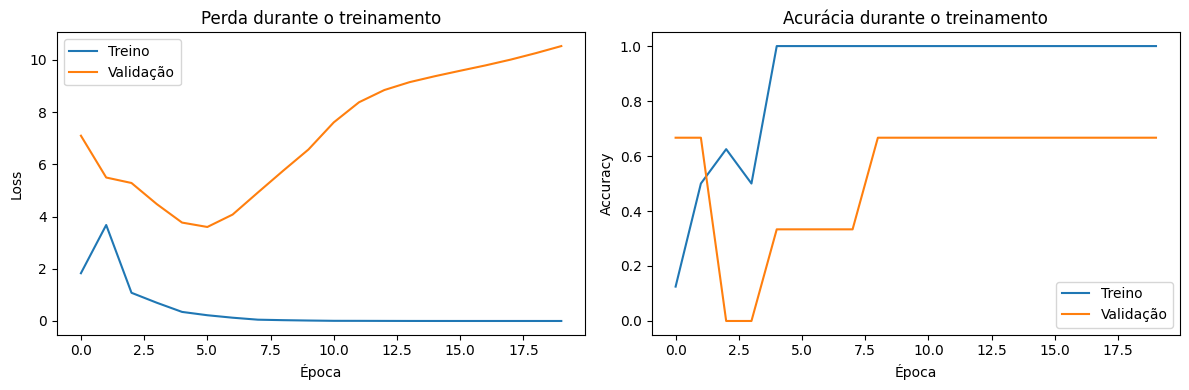

In [192]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(historico.history["loss"], label="Treino")
axes[0].plot(historico.history["val_loss"], label="Validação")
axes[0].set_title("Perda durante o treinamento")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(historico.history["accuracy"], label="Treino")
axes[1].plot(historico.history["val_accuracy"], label="Validação")
axes[1].set_title("Acurácia durante o treinamento")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

### 4.7 — Avaliação no conjunto de teste

Após o treinamento, o modelo é avaliado em imagens que não participaram do treinamento. Essa etapa fornece uma estimativa de como a CNN se comporta diante de exemplos não utilizados para ajustar seus parâmetros.

In [193]:
resultado_teste = model.evaluate(
    X_img_teste,
    y_img_teste,
    verbose=1
)

print("Loss no teste:", resultado_teste[0])
print("Accuracy no teste:", resultado_teste[1])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 417ms/step - accuracy: 0.5000 - loss: 7.6641
Loss no teste: 7.664111614227295
Accuracy no teste: 0.5


### 4.8 — Análise das previsões

As previsões são convertidas da saída probabilística da `softmax` para a classe com maior probabilidade. A comparação entre os rótulos reais e previstos permite identificar quais imagens foram classificadas corretamente.

In [194]:
y_pred_prob = model.predict(X_img_teste)
y_pred = np.argmax(y_pred_prob, axis=1)

print("Real:   ", y_img_teste)
print("Predito: ", y_pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 347ms/step
Real:    [2 4 4 2 0 5]
Predito:  [2 5 2 2 2 5]


### 4.9 — Matriz de confusão

A matriz de confusão compara as categorias reais com as categorias previstas pela CNN. Os valores na diagonal principal representam acertos; os valores fora da diagonal representam erros de classificação.

Real:    [2 4 4 2 0 5]
Predito: [2 5 2 2 2 5]


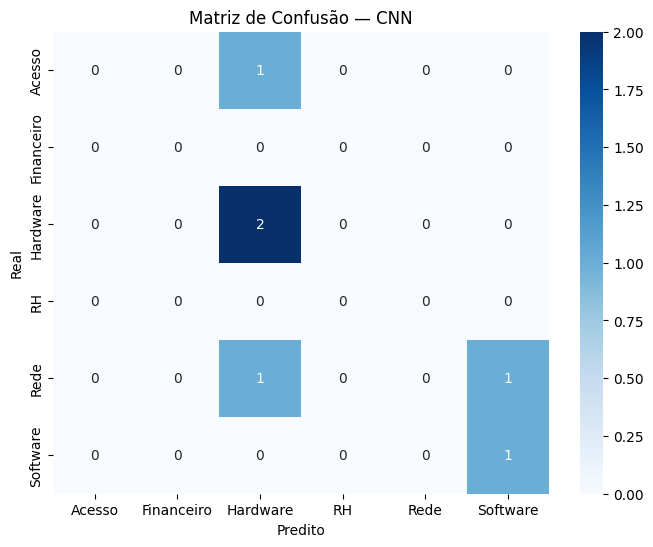

In [195]:
from sklearn.metrics import confusion_matrix

# Gerar as previsões do conjunto de teste
y_pred_prob = model.predict(X_img_teste, verbose=0)

# Transformar as probabilidades na classe prevista
y_pred = np.argmax(y_pred_prob, axis=1)

# Gerar a matriz de confusão
cm = confusion_matrix(
    y_img_teste,
    y_pred,
    labels=np.arange(len(le_imagens.classes_))
)

print("Real:   ", y_img_teste)
print("Predito:", y_pred)

# Visualização
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le_imagens.classes_,
    yticklabels=le_imagens.classes_
)

plt.xlabel('Predito')
plt.ylabel('Real')
plt.title('Matriz de Confusão — CNN')
plt.show()

### 4.10 — Discussão dos resultados

A CNN apresentou 100% de acurácia no conjunto de treinamento. Durante o treinamento, a acurácia de validação atingiu 66,7% em algumas épocas, mas esse resultado deve ser interpretado com cautela devido à quantidade reduzida de exemplos utilizados na validação.

No conjunto de teste, o modelo obteve **50% de acurácia, correspondendo a 3 acertos em 6 imagens**.

Apesar do resultado no teste, o treinamento atingiu 100% de acurácia, indicando que o modelo se ajustou muito bem aos exemplos utilizados no treinamento. Esse comportamento, associado à pequena quantidade de imagens disponíveis, sugere risco de overfitting e dificuldade de generalização.

A matriz de confusão mostra que o modelo acertou exemplos de Hardware e Software, mas apresentou erros nas demais previsões. Como o conjunto de teste contém apenas seis imagens, não é possível considerar essa avaliação uma estimativa robusta do desempenho do modelo.

Portanto, o experimento demonstra a aplicação de uma CNN para classificação das evidências visuais, mas evidencia limitações relacionadas à quantidade reduzida de imagens e à representatividade das categorias.

O resultado reforça a proposta multimodal do projeto: as imagens podem contribuir como uma fonte adicional de informação, mas a classificação dos chamados deve ser analisada em conjunto com os dados textuais e outras características disponíveis.

# 5. Transfer Learning

### 5.1 — Carregamento do modelo pré-treinado

In [196]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

### 5.2 — Construção do modelo

In [197]:
modelo_tl = models.Sequential([
    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dense(64, activation='relu'),

    layers.Dense(6, activation='softmax')
])

### 5.3 — Compilação do modelo

In [198]:
modelo_tl.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

### 5.4 — Pré-processamento das imagens

In [199]:

from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

X_img_treino_mobilenet = preprocess_input(
    X_img_treino.copy() * 255.0
)

X_img_teste_mobilenet = preprocess_input(
    X_img_teste.copy() * 255.0
)


### 5.5 — Treinamento do modelo

In [200]:
historico_tl = modelo_tl.fit(
    X_img_treino_mobilenet,
    y_img_treino,
    epochs=20,
    validation_split=0.2,
    verbose=1
)


Epoch 1/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 11s 11s/step - accuracy: 0.0000e+00 - loss: 2.7990 - val_accuracy: 0.3333 - val_loss: 1.7575
Epoch 2/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.5000 - loss: 1.4789 - val_accuracy: 0.6667 - val_loss: 1.4153
Epoch 3/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - accuracy: 0.8750 - loss: 0.7659 - val_accuracy: 0.6667 - val_loss: 1.3965
Epoch 4/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - accuracy: 0.8750 - loss: 0.4088 - val_accuracy: 0.6667 - val_loss: 1.4735
Epoch 5/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - accuracy: 1.0000 - loss: 0.2311 - val_accuracy: 0.6667 - val_loss: 1.5846
Epoch 6/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - accuracy: 1.0000 - loss: 0.1295 - val_accuracy: 0.6667 - val_loss: 1.7068
Epoch 7/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - accuracy: 1.0000 - loss: 0.0734 - val_accuracy: 0.6667 - val_loss: 1.8486
Epoch 8/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - accuracy: 1.0000 - loss: 0.0421 - val_accuracy: 0.6667 - val_lo

### 5.6 — Avaliação no conjunto de teste

In [201]:
resultado_teste_tl = modelo_tl.evaluate(
    X_img_teste_mobilenet,
    y_img_teste,
    verbose=1
)

print("Loss no teste:", resultado_teste_tl[0])
print("Accuracy no teste:", resultado_teste_tl[1])


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.3333 - loss: 3.1929
Loss no teste: 3.192919969558716
Accuracy no teste: 0.3333333432674408


### 5.7 — Análise das previsões

In [202]:
y_pred_prob_tl = modelo_tl.predict(
    X_img_teste_mobilenet,
    verbose=0
)

y_pred_tl = np.argmax(y_pred_prob_tl, axis=1)

print("Real:   ", y_img_teste)
print("Predito:", y_pred_tl)


Real:    [2 4 4 2 0 5]
Predito: [2 2 2 2 2 2]


### 5.8 — Matriz de Confusão — Transfer Learning

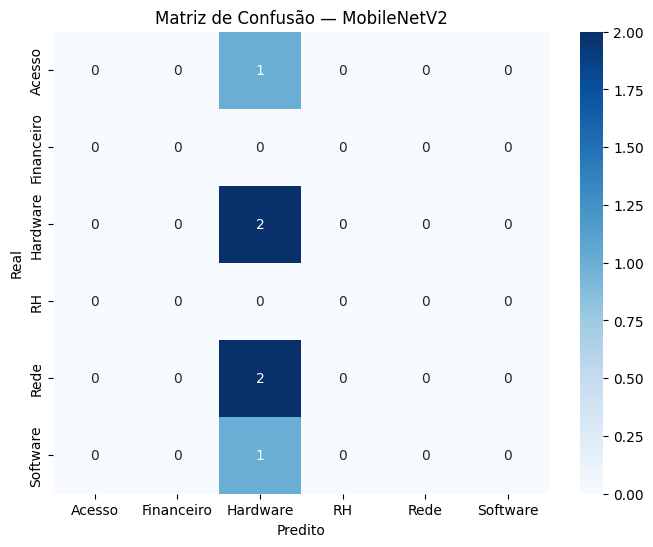

In [203]:
from sklearn.metrics import confusion_matrix

cm_tl = confusion_matrix(
    y_img_teste,
    y_pred_tl,
    labels=np.arange(len(le_imagens.classes_))
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_tl,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le_imagens.classes_,
    yticklabels=le_imagens.classes_
)

plt.xlabel('Predito')
plt.ylabel('Real')
plt.title('Matriz de Confusão — MobileNetV2')
plt.show()



### 5.9 — Análise dos resultados

O modelo MobileNetV2 obteve acurácia de 33,33% no conjunto de teste, classificando corretamente 2 das 6 imagens avaliadas.

A análise das previsões mostra que o modelo classificou todas as seis imagens como Hardware. Dessa forma, acertou as duas imagens dessa categoria, mas errou as imagens das categorias Acesso, Rede e Software presentes no conjunto de teste.

As categorias Financeiro e RH não possuem exemplos no conjunto de teste, impossibilitando avaliar o desempenho do modelo nessas classes.

Apesar do uso de transferência de aprendizado, os resultados ainda são limitados. A pequena quantidade de imagens disponíveis dificulta uma avaliação confiável da capacidade de generalização do modelo. Portanto, os resultados devem ser interpretados como um experimento inicial, e não como evidência de desempenho adequado para uso em produção.

# 6. ResNet50 — Transfer Learning

### 6.1 — Carregamento do modelo pré-treinado

In [204]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, models

base_model_resnet = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model_resnet.trainable = False

### 6.2 — Construção do modelo

In [205]:
modelo_resnet = models.Sequential([
    base_model_resnet,

    layers.GlobalAveragePooling2D(),

    layers.Dense(64, activation='relu'),

    layers.Dense(6, activation='softmax')
])

### 6.3 — Compilação do modelo

In [206]:
modelo_resnet.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

### 6.4 — Pré-processamento das imagens

In [207]:
from tensorflow.keras.applications.resnet50 import preprocess_input

X_img_treino_resnet = preprocess_input(
    X_img_treino.copy() * 255.0
)

X_img_teste_resnet = preprocess_input(
    X_img_teste.copy() * 255.0
)

### 6.5 — Treinamento da ResNet50

In [208]:
historico_resnet = modelo_resnet.fit(
    X_img_treino_resnet,
    y_img_treino,
    epochs=20,
    validation_split=0.2,
    verbose=1
)

Epoch 1/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 14s 14s/step - accuracy: 0.2500 - loss: 1.9190 - val_accuracy: 0.3333 - val_loss: 1.7611
Epoch 2/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step - accuracy: 0.7500 - loss: 0.6530 - val_accuracy: 0.3333 - val_loss: 2.0321
Epoch 3/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - accuracy: 1.0000 - loss: 0.2069 - val_accuracy: 0.3333 - val_loss: 2.3657
Epoch 4/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step - accuracy: 1.0000 - loss: 0.0786 - val_accuracy: 0.3333 - val_loss: 2.7291
Epoch 5/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - accuracy: 1.0000 - loss: 0.0385 - val_accuracy: 0.0000e+00 - val_loss: 3.0578
Epoch 6/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step - accuracy: 1.0000 - loss: 0.0215 - val_accuracy: 0.0000e+00 - val_loss: 3.3005
Epoch 7/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step - accuracy: 1.0000 - loss: 0.0129 - val_accuracy: 0.0000e+00 - val_loss: 3.4785
Epoch 8/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - accuracy: 1.0000 - loss: 0.0080 - val_accuracy: 0.0000e

### 6.6 — Avaliação no conjunto de teste

In [209]:
resultado_teste_resnet = modelo_resnet.evaluate(
    X_img_teste_resnet,
    y_img_teste,
    verbose=1
)

print("Loss no teste:", resultado_teste_resnet[0])
print("Accuracy no teste:", resultado_teste_resnet[1])

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.3333 - loss: 3.4244
Loss no teste: 3.424387216567993
Accuracy no teste: 0.3333333432674408


### 6.7 — Análise das previsões

In [210]:
y_pred_prob_resnet = modelo_resnet.predict(
    X_img_teste_resnet,
    verbose=0
)

y_pred_resnet = np.argmax(
    y_pred_prob_resnet,
    axis=1
)

print("Real:   ", y_img_teste)
print("Predito:", y_pred_resnet)

Real:    [2 4 4 2 0 5]
Predito: [2 5 2 2 2 4]


### 6.8 — Matriz de Confusão — ResNet50

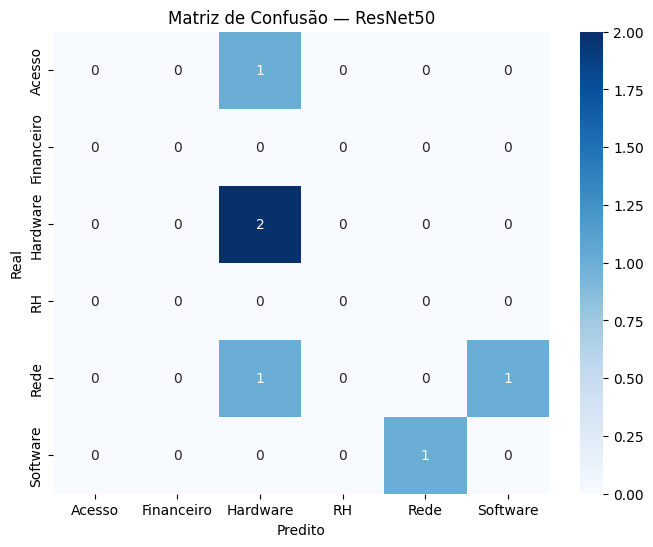

In [211]:
from sklearn.metrics import confusion_matrix

cm_resnet = confusion_matrix(
    y_img_teste,
    y_pred_resnet,
    labels=np.arange(len(le_imagens.classes_))
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_resnet,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le_imagens.classes_,
    yticklabels=le_imagens.classes_
)

plt.xlabel('Predito')
plt.ylabel('Real')
plt.title('Matriz de Confusão — ResNet50')
plt.show()

### 6.9 — Análise dos resultados

A ResNet50 apresentou acurácia de 33,33% no conjunto de teste, acertando 2 das 6 imagens avaliadas. Os dois acertos ocorreram na categoria Hardware.

A matriz de confusão evidencia uma concentração das previsões na categoria Hardware. A imagem de Acesso e uma das imagens de Rede foram classificadas incorretamente como Hardware. A outra imagem de Rede foi classificada como Software, enquanto a imagem de Software foi classificada como Rede.

O treinamento atingiu 100% de acurácia, mas o desempenho na validação permaneceu baixo e a perda de validação aumentou ao longo das épocas. Esse comportamento indica sinais de *overfitting*, sugerindo que o modelo se ajustou aos exemplos de treinamento sem generalizar adequadamente.

Os resultados devem ser interpretados com cautela, pois o experimento utilizou apenas 17 imagens com associação consistente entre imagem e categoria, sendo 11 destinadas ao treinamento e 6 ao teste. Portanto, essa avaliação é exploratória e não permite conclusões robustas sobre o desempenho da ResNet50 em um conjunto maior.

Apesar das limitações, o experimento demonstra a aplicação de *Transfer Learning* em Visão Computacional e reforça a importância de combinar imagens com dados textuais e outras informações dos chamados na abordagem multimodal do projeto.

# 7. Experimento complementar — ResNet50 com conjunto ampliado

### 7.1 — Preparação do conjunto ampliado

In [212]:
import os

# Reaproveita o repositório já clonado no início do notebook.
pasta_repositorio = str(raiz_projeto)
pasta_imagens = str(caminho_imagens)

arquivos_imagem = [
    arquivo for arquivo in os.listdir(pasta_imagens)
    if arquivo.lower().endswith((".png", ".jpg", ".jpeg"))
]

print("Pasta encontrada:", os.path.exists(pasta_imagens))
print("Total de arquivos de imagem:", len(arquivos_imagem))

Pasta encontrada: True
Total de arquivos de imagem: 26


### 7.2 — Montagem do conjunto ampliado

In [213]:
# Categoria predominante de cada imagem
rotulos_todas_imagens = distribuicao_imagens.idxmax(axis=1).to_dict()

print("Total de imagens:", len(rotulos_todas_imagens))
print("\nImagem -> categoria atribuída:")

for imagem, categoria in sorted(rotulos_todas_imagens.items()):
    print(f"{imagem} -> {categoria}")

Total de imagens: 26

Imagem -> categoria atribuída:
images/access_denied.png -> Acesso
images/browser.png -> Software
images/cooler.png -> Hardware
images/default_access.png -> Acesso
images/default_finance.png -> Financeiro
images/default_hardware.png -> Hardware
images/default_hr.png -> RH
images/default_network.png -> Rede
images/default_software.png -> Software
images/email.png -> Software
images/finance_report.png -> Financeiro
images/hard_drive.png -> Hardware
images/hr_portal.png -> RH
images/keyboard.png -> Hardware
images/login.png -> Acesso
images/monitor.png -> Hardware
images/motherboard.png -> Hardware
images/mouse.png -> Hardware
images/network.png -> Rede
images/office.png -> Software
images/payroll.png -> RH
images/power_supply.png -> Hardware
images/recruitment.png -> RH
images/sap_erp.png -> Software
images/server.png -> Rede
images/vpn.png -> Rede


### 7.3 — Carregamento e validação das imagens

In [214]:
import os

arquivos_rotulados = [
    os.path.join(pasta_imagens, caminho.replace("images/", ""))
    for caminho in rotulos_todas_imagens
]

arquivos_inexistentes = [
    arquivo for arquivo in arquivos_rotulados
    if not os.path.isfile(arquivo)
]

print("Total de imagens do conjunto ampliado:", len(arquivos_rotulados))
print("Arquivos inexistentes:", len(arquivos_inexistentes))

if arquivos_inexistentes:
    print("\nImagens não encontradas:")
    for arquivo in arquivos_inexistentes:
        print(arquivo)


Total de imagens do conjunto ampliado: 26
Arquivos inexistentes: 0


### 7.4 — Preparação das imagens

In [215]:
import numpy as np
from tensorflow.keras.utils import load_img, img_to_array
from sklearn.preprocessing import LabelEncoder

X_imagens_ampliadas = []
y_categorias_texto = []

for caminho, categoria in rotulos_todas_imagens.items():
    caminho_arquivo = os.path.join(
        pasta_repositorio, "data", "raw", caminho
    )

    imagem = load_img(
        caminho_arquivo,
        target_size=(224, 224)
    )

    imagem_array = img_to_array(imagem) / 255.0

    X_imagens_ampliadas.append(imagem_array)
    y_categorias_texto.append(categoria)

X_imagens_ampliadas = np.array(X_imagens_ampliadas)

# Mantém as seis categorias na mesma ordem
categorias = [
    "Acesso", "Financeiro", "Hardware",
    "RH", "Rede", "Software"
]

codificador_ampliado = LabelEncoder()
codificador_ampliado.fit(categorias)

y_categorias_ampliadas = codificador_ampliado.transform(
    y_categorias_texto
)

print("Formato das imagens:", X_imagens_ampliadas.shape)
print("Total de rótulos:", len(y_categorias_ampliadas))
print("Categorias:", list(codificador_ampliado.classes_))

Formato das imagens: (26, 224, 224, 3)
Total de rótulos: 26
Categorias: [np.str_('Acesso'), np.str_('Financeiro'), np.str_('Hardware'), np.str_('RH'), np.str_('Rede'), np.str_('Software')]


### 7.5 — Separação em treino e teste

In [216]:
from sklearn.model_selection import train_test_split

X_treino_ampliado, X_teste_ampliado, y_treino_ampliado, y_teste_ampliado = train_test_split(
    X_imagens_ampliadas,
    y_categorias_ampliadas,
    test_size=0.30,
    random_state=42
)

print("Imagens para treinamento:", len(X_treino_ampliado))
print("Imagens para teste:", len(X_teste_ampliado))

Imagens para treinamento: 18
Imagens para teste: 8


### 7.6 — Criação do modelo ResNet50 com dados ampliados

In [217]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout

# Carregar a arquitetura ResNet50 pré-treinada no ImageNet
base_model_resnet_ampliado = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Congelar as camadas pré-treinadas
base_model_resnet_ampliado.trainable = False

# Criar um novo classificador
modelo_resnet_ampliado = Sequential([
    base_model_resnet_ampliado,
    GlobalAveragePooling2D(),
    Dense(128, activation="relu"),
    Dropout(0.3),
    Dense(6, activation="softmax")
])

modelo_resnet_ampliado.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

modelo_resnet_ampliado.summary()

Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_11     │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,758 (90.98 MB)

 Trainable params: 263,046 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

### 7.7 — Pré-processamento e treinamento

In [218]:
# Pré-processamento específico da ResNet50
X_treino_resnet_ampliado = preprocess_input(
    X_treino_ampliado.copy() * 255.0
)

X_teste_resnet_ampliado = preprocess_input(
    X_teste_ampliado.copy() * 255.0
)

# Treinamento do novo modelo
historico_resnet_ampliado = modelo_resnet_ampliado.fit(
    X_treino_resnet_ampliado,
    y_treino_ampliado,
    epochs=15,
    batch_size=4,
    validation_split=0.2,
    verbose=1
)

Epoch 1/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step - accuracy: 0.2857 - loss: 2.9920 - val_accuracy: 0.0000e+00 - val_loss: 5.1310
Epoch 2/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.7857 - loss: 0.9328 - val_accuracy: 0.0000e+00 - val_loss: 4.1317
Epoch 3/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 1.0000 - loss: 0.2180 - val_accuracy: 0.0000e+00 - val_loss: 4.1572
Epoch 4/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.8571 - loss: 0.6079 - val_accuracy: 0.0000e+00 - val_loss: 3.7413
Epoch 5/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 1.0000 - loss: 0.0641 - val_accuracy: 0.2500 - val_loss: 3.6685
Epoch 6/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.9286 - loss: 0.1041 - val_accuracy: 0.0000e+00 - val_loss: 3.9965
Epoch 7/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 1.0000 - loss: 0.0366 - val_accuracy: 0.0000e+00 - val_loss: 4.2446
Epoch 8/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 1.0000 - loss: 0.0117 - val_accuracy: 0.0

### 7.8 — Avaliação do modelo ResNet50 com dados ampliados

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
Acurácia no teste: 37.50%

Relatório de classificação:
              precision    recall  f1-score   support

      Acesso       0.00      0.00      0.00         1
  Financeiro       0.00      0.00      0.00         0
    Hardware       0.50      1.00      0.67         3
          RH       0.00      0.00      0.00         0
        Rede       0.00      0.00      0.00         1
    Software       0.00      0.00      0.00         3

    accuracy                           0.38         8
   macro avg       0.08      0.17      0.11         8
weighted avg       0.19      0.38      0.25         8



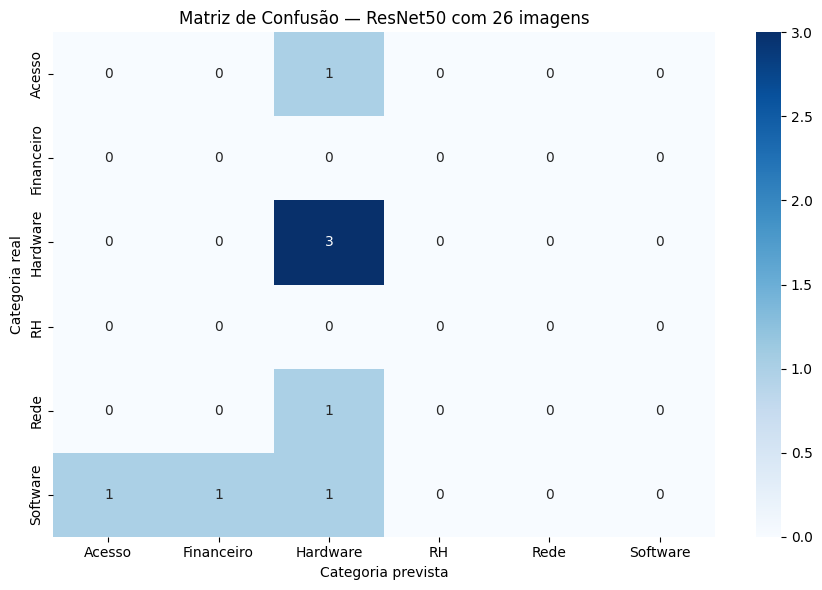

In [219]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Fazer previsões nas imagens de teste
y_pred_prob_ampliado = modelo_resnet_ampliado.predict(
    X_teste_resnet_ampliado
)

y_pred_ampliado = np.argmax(y_pred_prob_ampliado, axis=1)

# Acurácia
acuracia_ampliada = accuracy_score(
    y_teste_ampliado,
    y_pred_ampliado
)

print(f"Acurácia no teste: {acuracia_ampliada:.2%}")

# Relatório de classificação
print("\nRelatório de classificação:")

print(classification_report(
    y_teste_ampliado,
    y_pred_ampliado,
    labels=np.arange(len(codificador_ampliado.classes_)),
    target_names=codificador_ampliado.classes_,
    zero_division=0
))

# Matriz de confusão visual
matriz = confusion_matrix(
    y_teste_ampliado,
    y_pred_ampliado,
    labels=np.arange(len(codificador_ampliado.classes_))
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=codificador_ampliado.classes_,
    yticklabels=codificador_ampliado.classes_
)

plt.title("Matriz de Confusão — ResNet50 com 26 imagens")
plt.xlabel("Categoria prevista")
plt.ylabel("Categoria real")
plt.tight_layout()
plt.show()

### 7.9 — Comparação dos resultados

In [221]:
import pandas as pd
from collections import Counter

def acuracia_baseline(y_treino, y_teste):
    classe_majoritaria = Counter(y_treino).most_common(1)[0][0]
    return (y_teste == classe_majoritaria).mean() * 100

baseline_17 = acuracia_baseline(y_img_treino, y_img_teste)
baseline_26 = acuracia_baseline(y_treino_ampliado, y_teste_ampliado)

comparacao_experimentos = pd.DataFrame({
    "Experimento": [
        "CNN",
        "MobileNetV2",
        "ResNet50 original",
        "ResNet50 com 26 imagens"
    ],
    "Imagens utilizadas": [17, 17, 17, 26],
    "Acurácia no teste (%)": [
        resultado_teste[1] * 100,
        resultado_teste_tl[1] * 100,
        resultado_teste_resnet[1] * 100,
        acuracia_ampliada * 100
    ],
    "Baseline: classe mais frequente (%)": [
        baseline_17, baseline_17, baseline_17, baseline_26
    ]
})

display(
    comparacao_experimentos.style.format({
        "Acurácia no teste (%)": "{:.2f}%",
        "Baseline: classe mais frequente (%)": "{:.2f}%"
    })
)

,Experimento,Imagens utilizadas,Acurácia no teste (%),Baseline: classe mais frequente (%)
0,CNN,17,50.00%,33.33%
1,MobileNetV2,17,33.33%,33.33%
2,ResNet50 original,17,33.33%,33.33%
3,ResNet50 com 26 imagens,26,37.50%,37.50%


### 7.10 — Conclusão do experimento adicional

Neste experimento complementar, a base de imagens foi ampliada de 17 para 26 imagens distintas, utilizando a arquitetura ResNet50 com pesos pré-treinados no ImageNet. O modelo alcançou 37,5% de acurácia no conjunto de teste, correspondendo a 3 acertos em 8 imagens.

Durante o treinamento, o modelo atingiu 100% de acurácia nos dados de treinamento, enquanto o desempenho na validação permaneceu baixo e instável. Esse comportamento indica sinais de sobreajuste (*overfitting*), sugerindo dificuldade de generalização para imagens não utilizadas durante o treinamento.

A ampliação da base permitiu incluir mais imagens no experimento. Entretanto, nove imagens estavam associadas a múltiplas categorias nos chamados, sendo atribuídas à categoria predominante. Esse procedimento possibilitou o treinamento supervisionado, mas pode introduzir ruído nos rótulos, pois a categoria predominante não garante que a imagem represente exclusivamente aquela classe.

Os resultados não permitem concluir que a ampliação da base tenha melhorado ou prejudicado o desempenho do modelo, pois os conjuntos de teste são diferentes e possuem poucos exemplos. Além disso, as categorias Financeiro e RH não tiveram imagens no conjunto de teste deste experimento, impossibilitando avaliar o desempenho nessas classes.

A comparação com o *baseline*, que prevê sempre a classe mais frequente no conjunto de treinamento, mostrou o mesmo resultado de acurácia: 37,5%. Os três acertos do modelo ocorreram na categoria Hardware, enquanto nenhuma das três imagens de Software do conjunto de teste foi classificada corretamente. Portanto, o modelo não superou essa estratégia de referência em termos de acurácia.

O experimento evidencia a importância de ampliar a quantidade de imagens distintas, validar os rótulos e utilizar conjuntos de teste mais representativos. Apesar das limitações, contribui para investigar o uso de imagens como fonte complementar de informação na classificação multimodal dos chamados.

## 8. Conclusão geral

Este notebook apresentou o desenvolvimento do módulo de Visão Computacional do projeto, com o objetivo de investigar o uso das imagens anexadas aos chamados como fonte complementar de informação para a classificação das categorias.

Inicialmente, foram realizadas a inspeção e a preparação das imagens, incluindo o redimensionamento, a normalização dos pixels e a associação entre imagens e categorias. A análise identificou 26 imagens distintas, das quais 17 possuíam associação consistente com uma única categoria e 9 estavam associadas a múltiplas categorias.

Foram conduzidos experimentos com uma Rede Neural Convolucional (CNN), desenvolvida e treinada desde o início, e com modelos pré-treinados por transferência de aprendizado (*Transfer Learning*), utilizando MobileNetV2 e ResNet50. Nos resultados registrados, a CNN obteve 50% de acurácia no conjunto de teste, enquanto MobileNetV2 e ResNet50 original alcançaram 33,33%.

Também foi realizado um experimento complementar com a ResNet50 utilizando as 26 imagens disponíveis e atribuindo às imagens associadas a múltiplas categorias o rótulo da categoria predominante nos chamados relacionados. Nesse experimento, a acurácia no conjunto de teste foi de 37,5%, correspondendo a 3 acertos em 8 imagens.

Os experimentos apresentam limitações importantes. A quantidade reduzida de imagens distintas, o número limitado de exemplos nos conjuntos de teste, a ausência de algumas categorias no teste do experimento ampliado e os sinais de *overfitting* dificultam a avaliação da capacidade de generalização dos modelos. Além disso, a atribuição de categorias predominantes às imagens associadas a múltiplas classes pode introduzir ruído nos rótulos.

A comparação com uma linha de base (*baseline*), que prevê sempre a classe mais frequente no conjunto de treinamento, também ajuda a contextualizar os resultados. Essa referência obteve 33,33% nos experimentos com 17 imagens e 37,5% no experimento ampliado. A CNN alcançou 50%, ficando acima da referência, enquanto a MobileNetV2 e a ResNet50 original igualaram seus respectivos *baselines*. A ResNet50 ampliada também igualou a referência, sem superá-la em acurácia. Portanto, os modelos não demonstraram desempenho consistentemente superior à estratégia de prever a categoria mais frequente.

Diante dessas limitações, os resultados devem ser considerados exploratórios. Eles demonstram a aplicação de técnicas de Visão Computacional ao problema proposto, mas não são suficientes para afirmar que os modelos estejam prontos para uso em produção.

Como próximos passos, recomenda-se ampliar a base com imagens distintas e rótulos validados, construir conjuntos de treinamento, validação e teste mais representativos e avaliar os modelos com métricas específicas por categoria. Também é importante investigar como as informações visuais podem complementar os dados textuais e outras características dos chamados.

Por fim, este módulo contribui para a proposta multimodal do projeto ao explorar as imagens como fonte complementar de informação. A integração com as demais modalidades poderá permitir uma análise mais abrangente dos chamados e apoiar o desenvolvimento de uma abordagem de classificação mais consistente.